# 06.6 · Solutions

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cloudops-one/training-ai-ml/blob/main/modules/06-unsupervised/06-pca/solutions.ipynb)

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings; warnings.filterwarnings("ignore")

## Exercise 1

Mean (2.5, 5). Deviations x: −1.5, −0.5, 0.5, 1.5; y: −3, −1, 1, 3.

- Var(x) = (2.25 + 0.25 + 0.25 + 2.25) / 3 = 5/3 ≈ 1.667
- Var(y) = (9 + 1 + 1 + 9) / 3 = 20/3 ≈ 6.667
- Cov(x, y) = (4.5 + 0.5 + 0.5 + 4.5) / 3 = 10/3 ≈ 3.333

The points lie exactly on the line y = 2x, so all the spread is along one direction: the eigenvalues are 25/3 ≈ 8.333 and **0**, and PC1 explains **100%**. PC1 points along (1, 2)/√5 ≈ (0.447, 0.894).

In [2]:
P = np.array([[1, 2], [2, 4], [3, 6], [4, 8]], dtype=float)
C = np.cov(P, rowvar=False)
w, V = np.linalg.eigh(C)
print("covariance:\n", C.round(3))
print("eigenvalues:", w.round(3), " ratio:", (w[::-1] / w.sum()).round(3))
print("PC1:", np.abs(V[:, -1]).round(3))

covariance:
 [[1.667 3.333]
 [3.333 6.667]]
eigenvalues: [0.    8.333]  ratio: [1. 0.]
PC1: [0.447 0.894]


## Exercise 2

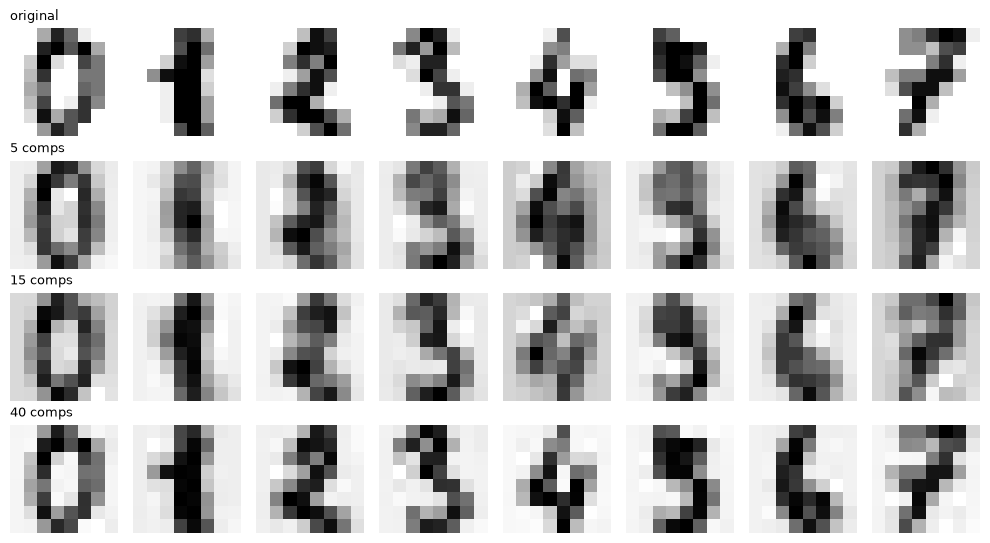

In [3]:
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
X_dig, y_dig = load_digits(return_X_y=True)

fig, ax = plt.subplots(4, 8, figsize=(10, 5.5))
for r, k in enumerate([None, 5, 15, 40]):
    imgs = X_dig[:8] if k is None else PCA(k).fit(X_dig).inverse_transform(PCA(k).fit(X_dig).transform(X_dig[:8]))
    for c in range(8):
        ax[r, c].imshow(imgs[c].reshape(8, 8), cmap="gray_r"); ax[r, c].axis("off")
    ax[r, 0].set_title("original" if k is None else f"{k} comps", fontsize=9, loc="left")
plt.tight_layout(); plt.show()

With 5 components the shapes are blurry blobs, though some digits are guessable; by 15 most are readable; 40 is nearly identical to the original. This matches the cumulative-variance curve: 5 components hold 55% of the variance, 15 hold 84% and 40 hold 99%.

## Exercise 3

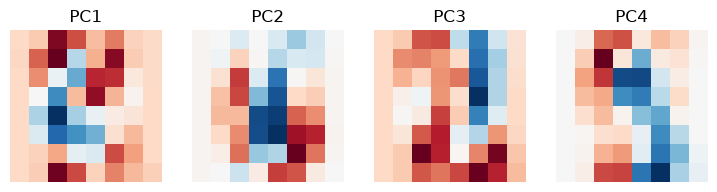

In [4]:
comps = PCA().fit(X_dig).components_
fig, ax = plt.subplots(1, 4, figsize=(9, 2.5))
for i in range(4):
    ax[i].imshow(comps[i].reshape(8, 8), cmap="RdBu"); ax[i].set_title(f"PC{i+1}"); ax[i].axis("off")
plt.show()

Each component is a pattern of pixels that brighten (one colour) while others darken (the other). PC1 roughly contrasts a "0-like" ring against a central vertical stroke, which separates 0s from 1s; later components pick out other strokes (top bar, left curve). They are not neat parts of digits, just the directions of largest variation.

## Exercise 4

In [5]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
rng = np.random.default_rng(0)
x1 = rng.normal(0, 10, 2000); x2 = rng.normal(0, 1, 2000)
X = np.column_stack([x1, x2]); y = (x2 > 0).astype(int)

pc1 = PCA(1).fit_transform(X)
print("PC1 only:     ", cross_val_score(LogisticRegression(), pc1, y, cv=5).mean().round(3))
print("both features:", cross_val_score(LogisticRegression(), X, y, cv=5).mean().round(3))

PC1 only:      0.5
both features: 0.996


PC1 follows `x1`, the noisy column with the biggest variance, so a model on PC1 alone is close to a coin flip. All the signal sat in the low-variance `x2`, which PCA discarded. **PCA keeps spread, not usefulness.** It is unsupervised: it never looks at the target.